In [ ]:
pip install geopandas pyarrow.parquet matplotlib.plot numpy

In [1]:
import pandas as pd
import geopandas as gpd
import numpy as np

pd.set_option("display.max_columns", None)

In [ ]:
blocks_gdf = gpd.read_parquet("data/Cartografia_censo2024_Pais_Manzanas.parquet")
blocks_gdf = blocks_gdf[blocks_gdf.COMUNA == "CONCEPCIÓN"]

In [105]:
blocks_df = pd.read_csv("data/Base_manzana_entidad_CPV24.csv", sep=";")
blocks_df = blocks_df[blocks_df.COMUNA == "CONCEPCIÓN"]

/tmp/ipykernel_4005/1176615123.py:1: DtypeWarning: Columns (24,25,26,27,28,29,30,31,32,40,41,42,43,44,45,46,47,48,49,50,51,52,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87,88,89,90,91,92,93,94,95,96,97,98,99,100,101,102,103,104,105,106,107) have mixed types. Specify dtype option on import or set low_memory=False.
  blocks_df = pd.read_csv("data/Base_manzana_entidad_CPV24.csv", sep=";")


In [106]:
blocks_df.columns.tolist()

['CONTENEDOR_COMUNAL',
 'COD_REGION',
 'REGION',
 'PROVINCIA',
 'CUT',
 'COMUNA',
 'AREA_C',
 'MANZENT',
 'DISTRITO',
 'COD_DISTRITO',
 'COD_LOCALIDAD',
 'COD_ZONA',
 'LOCALIDAD',
 'COD_ENTIDAD',
 'COD_MANZANA',
 'ENTIDAD',
 'TIPO_MZ',
 'COD_CATEGORIA',
 'CATEGORIA',
 'ID_ENTIDAD',
 'ID_LOCALIDAD',
 'ID_DISTRITO',
 'ID_ZONA',
 'n_per',
 'n_hombres',
 'n_mujeres',
 'n_edad_0_5',
 'n_edad_6_13',
 'n_edad_14_17',
 'n_edad_18_24',
 'n_edad_25_44',
 'n_edad_45_59',
 'n_edad_60_mas',
 'prom_edad',
 'n_inmigrantes',
 'n_nacionalidad',
 'n_pueblos_orig',
 'n_afrodescendencia',
 'n_lengua_indigena',
 'n_religion',
 'n_dificultad_ver',
 'n_dificultad_oir',
 'n_dificultad_mover',
 'n_dificultad_cogni',
 'n_dificultad_cuidado',
 'n_dificultad_comunic',
 'n_discapacidad',
 'n_estcivcon_casado',
 'n_estcivcon_conviviente',
 'n_estcivcon_conv_civil',
 'n_estcivcon_anul_sep_div',
 'n_estcivcon_viudo',
 'n_estcivcon_soltero',
 'prom_escolaridad18',
 'n_asistencia_parv',
 'n_asistencia_basica',
 'n_asis

In [249]:
viv_df

,id_vivienda,region,provincia,comuna,comuna_bajo_umbral,area,tipo_operativo,cant_hog,cant_per,p2_tipo_vivienda,p3a_estado_ocupacion,p3b_estado_ocupacion,p4a_mat_paredes,p4b_mat_techo,p4c_mat_piso,p5_num_dormitorios,p6_fuente_agua,p7_distrib_agua,p8_serv_hig,p9_fuente_elect,p10_basura,p11a_num_personas,p11b_comparte_gasto,p11c_num_hogar,indice_hacinamiento,tipo_viv
63,64,8,81,8101,2,1,2,1.0,3,3.0,1.0,1.0,1.0,3.0,1.0,3.0,1.0,1.0,1.0,1.0,1.0,3.0,1.0,NaN,1.0,depto
114,115,8,81,8101,2,1,2,1.0,3,1.0,1.0,1.0,2.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,1.0,3.0,1.0,NaN,1.0,casa
125,126,8,81,8101,2,1,2,1.0,4,3.0,1.0,1.0,1.0,2.0,1.0,3.0,1.0,1.0,1.0,1.0,1.0,4.0,1.0,NaN,1.0,depto
176,177,8,81,8101,2,1,2,1.0,1,1.0,1.0,1.0,1.0,3.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,NaN,NaN,1.0,casa
177,178,8,81,8101,2,1,2,1.0,1,3.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,NaN,NaN,1.0,depto
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7664132,7664133,8,81,8101,2,1,2,1.0,3,1.0,1.0,1.0,3.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,1.0,3.0,1.0,NaN,1.0,casa
7664141,7664142,8,81,8101,2,1,2,1.0,1,3.0,1.0,1.0,1.0,3.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,NaN,NaN,1.0,depto
7664351,7664352,8,81,8101,2,1,2,1.0,2,3.0,1.0,1.0,1.0,2.0,1.0,2.0,1.0,1.0,1.0,1.0,1.0,2.0,1.0,NaN,1.0,depto
7664355,7664356,8,81,8101,2,1,2,1.0,3,3.0,1.0,1.0,1.0,3.0,1.0,3.0,1.0,1.0,1.0,1.0,1.0,3.0,1.0,NaN,1.0,depto


In [3]:
per_df = pd.read_parquet("data/personas_censo2024.parquet")
# per_df = per_df[per_df.provincia == 81]
per_df = per_df[per_df.comuna == 8101]
per_df

,id_vivienda,id_hogar,id_persona,region,provincia,comuna,comuna_bajo_umbral,area,tipo_operativo,sexo,edad,edad_quinquenal,parentesco,p23_est_civil,p24_lug_resid5,p24_lug_resid5_esp,p25_lug_nacimiento,p25_lug_nacimiento_rec,p25_lug_nacimiento_esp,p26_llegada_periodo,p27_nacionalidad,p27_nacionalidad_esp,p27_nacionalidad_rec,p28_autoid_pueblo,p28_pueblo_pert,p29_afrodescendencia_rec,p29_afrodescendencia,p30_lengua_indigena,p30_lengua_indigena_rec,p31_religion,p31_religion_rec,p32a_dificultad_ver,p32b_dificultad_oir,p32c_dificultad_mover,p32d_dificultad_cogni,p32e_dificultad_cuidado,p32f_dificultad_comunic,discapacidad,p33_edu_asiste,asistencia_parv,asistencia_basica,asistencia_media,asistencia_superior,p37_alfabet,escolaridad,cine11,sit_fuerza_trabajo,p40_cise_rec,depend_econ_deficit_hab,cod_ciuo,cod_caenes,p44_lug_trab,p44_lug_trab_esp,p45_medio_transporte,p46a_tot_hijs_nac,p46b_hijas_nac,p46c_hijos_nac,p47a_tot_hijs_sobrev,p47b_hijas_sobrev,p47c_hijos_sobrev,p48_anio_nac_uh,p48_mes_nac_uh,div_genero
153,64,1,1,8,81,8101,2,1,2,2,29,25,1,2.0,3,8108.0,2,1,8108,NaN,1,152,1,2,NaN,2,7,9.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,2,NaN,NaN,NaN,NaN,1.0,16,9,1.0,2.0,1,2.0,999,3.0,8112.0,2.0,1.0,1.0,0.0,1.0,1.0,0.0,2024.0,2.0,2.0
154,64,1,2,8,81,8101,2,1,2,1,39,35,4,2.0,3,8108.0,2,1,9101,NaN,1,152,1,1,1.0,2,7,9.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,2,NaN,NaN,NaN,NaN,1.0,15,6,1.0,1.0,1,8.0,G,3.0,8108.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0
155,64,1,3,8,81,8101,2,1,2,2,0,0,5,NaN,1,NaN,1,1,8101,NaN,1,152,1,1,1.0,2,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,2.0,NaN,NaN,NaN,NaN,0,1,NaN,NaN,2,NaN,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
270,115,1,1,8,81,8101,2,1,2,2,75,75,1,1.0,2,8101.0,1,1,8101,NaN,1,152,1,2,NaN,2,7,9.0,2.0,1.0,1.0,1.0,1.0,3.0,1.0,1.0,1.0,1.0,2,NaN,NaN,NaN,NaN,1.0,8,5,3.0,NaN,2,NaN,None,NaN,NaN,NaN,3.0,1.0,2.0,3.0,1.0,2.0,1986.0,9.0,2.0
271,115,1,2,8,81,8101,2,1,2,1,71,70,2,1.0,2,8101.0,1,1,8101,NaN,1,152,1,2,NaN,2,7,9.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,2,NaN,NaN,NaN,NaN,1.0,9,5,3.0,NaN,1,NaN,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18480170,7664352,1,2,8,81,8101,2,1,2,2,33,30,2,1.0,2,8101.0,2,1,8203,NaN,1,152,1,2,NaN,2,7,9.0,2.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,2,NaN,NaN,NaN,NaN,1.0,19,9,1.0,1.0,1,2.0,Q,2.0,8101.0,1.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0
18480179,7664356,1,1,8,81,8101,2,1,2,2,24,20,1,8.0,2,8101.0,2,1,8304,NaN,1,152,1,2,NaN,2,7,9.0,2.0,12.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,2,NaN,NaN,NaN,2.0,1.0,19,10,1.0,1.0,1,2.0,M,1.0,8101.0,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0
18480180,7664356,1,2,8,81,8101,2,1,2,2,26,25,15,8.0,2,8101.0,2,1,2201,NaN,1,152,1,2,NaN,2,7,9.0,2.0,12.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,1,NaN,NaN,NaN,NaN,1.0,19,9,1.0,2.0,1,2.0,P,2.0,8101.0,2.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0
18480181,7664356,1,3,8,81,8101,2,1,2,2,25,25,15,8.0,2,8101.0,2,1,10301,NaN,1,152,1,2,NaN,2,7,9.0,2.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,1,NaN,NaN,NaN,NaN,1.0,19,9,1.0,2.0,1,5.0,G,2.0,8101.0,2.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0


In [4]:
viv_df = pd.read_parquet("data/viviendas_censo2024.parquet")
# viv_df = viv_df[viv_df.provincia == 81]
viv_df = viv_df[viv_df.comuna == 8101]
viv_df

,id_vivienda,region,provincia,comuna,comuna_bajo_umbral,area,tipo_operativo,cant_hog,cant_per,p2_tipo_vivienda,p3a_estado_ocupacion,p3b_estado_ocupacion,p4a_mat_paredes,p4b_mat_techo,p4c_mat_piso,p5_num_dormitorios,p6_fuente_agua,p7_distrib_agua,p8_serv_hig,p9_fuente_elect,p10_basura,p11a_num_personas,p11b_comparte_gasto,p11c_num_hogar,indice_hacinamiento
63,64,8,81,8101,2,1,2,1.0,3,3.0,1.0,1.0,1.0,3.0,1.0,3.0,1.0,1.0,1.0,1.0,1.0,3.0,1.0,NaN,1.0
114,115,8,81,8101,2,1,2,1.0,3,1.0,1.0,1.0,2.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,1.0,3.0,1.0,NaN,1.0
125,126,8,81,8101,2,1,2,1.0,4,3.0,1.0,1.0,1.0,2.0,1.0,3.0,1.0,1.0,1.0,1.0,1.0,4.0,1.0,NaN,1.0
176,177,8,81,8101,2,1,2,1.0,1,1.0,1.0,1.0,1.0,3.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,NaN,NaN,1.0
177,178,8,81,8101,2,1,2,1.0,1,3.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,NaN,NaN,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7664132,7664133,8,81,8101,2,1,2,1.0,3,1.0,1.0,1.0,3.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,1.0,3.0,1.0,NaN,1.0
7664141,7664142,8,81,8101,2,1,2,1.0,1,3.0,1.0,1.0,1.0,3.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,NaN,NaN,1.0
7664351,7664352,8,81,8101,2,1,2,1.0,2,3.0,1.0,1.0,1.0,2.0,1.0,2.0,1.0,1.0,1.0,1.0,1.0,2.0,1.0,NaN,1.0
7664355,7664356,8,81,8101,2,1,2,1.0,3,3.0,1.0,1.0,1.0,3.0,1.0,3.0,1.0,1.0,1.0,1.0,1.0,3.0,1.0,NaN,1.0


---
# Simulated Annealing

### definicion de variables

In [155]:
per_att_df = pd.DataFrame(data=[
    ["n_per", 1.0],
    ["n_hombres", 1.0],
    ["n_mujeres", 1.0],
    ["n_edad_0_5", 1.0],
    ["n_edad_6_13", 1.0],
    ["n_edad_14_17", 1.0],
    ["n_edad_18_24", 1.0],
    ["n_edad_25_44", 1.0],
    ["n_edad_45_59", 1.0],
    ["n_edad_60_mas", 1.0],
], columns=["name", "weight"])

In [258]:
viv_att_df = pd.DataFrame(data=[
    ["n_vp", 1.0],

    ["n_dormitorios_1", 1.0],
    ["n_dormitorios_2", 1.0],
    ["n_dormitorios_3", 1.0],
    ["n_dormitorios_4", 1.0],
    ["n_dormitorios_5", 1.0],
    ["n_dormitorios_6_o_mas", 1.0],

    ["n_mat_paredes_hormigon", 1.0],
    ["n_mat_paredes_albanileria", 1.0],
    ["n_mat_paredes_tabique_forrado", 1.0],
    ["n_mat_paredes_tabique_sin_forro", 1.0],
    ["n_mat_paredes_artesanal", 1.0],
    ["n_mat_paredes_precarios", 1.0],
    
], columns=["name", "weight"])

In [266]:
att_df = pd.concat([per_att_df, viv_att_df])
att_df

,name,weight
0,n_per,1.0
1,n_hombres,1.0
2,n_mujeres,1.0
3,n_edad_0_5,1.0
4,n_edad_6_13,1.0
5,n_edad_14_17,1.0
6,n_edad_18_24,1.0
7,n_edad_25_44,1.0
8,n_edad_45_59,1.0
9,n_edad_60_mas,1.0


### preprocesar

In [259]:
# por cada variable en attributes debe haber una asignación

houses_df = (
    per_df.assign(
        n_per = 1,
        n_hombres = lambda x: x.sexo == 1,
        n_mujeres = lambda x: x.sexo == 2,
        n_edad_0_5 = lambda x: x.edad <= 5,
        n_edad_6_13 = lambda x: x.edad.between(6, 13),
        n_edad_14_17 = lambda x: x.edad.between(14, 17),
        n_edad_18_24 = lambda x: x.edad.between(18, 24),
        n_edad_25_44 = lambda x: x.edad.between(25, 44),
        n_edad_45_59 = lambda x: x.edad.between(45, 59),
        n_edad_60_mas = lambda x: x.edad >= 60,
    )[[
        "id_vivienda",
        *per_att_df.name
    ]]
    .groupby("id_vivienda")
    .sum()
    .reset_index()
)
houses_df = houses_df.set_index("id_vivienda")

houses_df

,n_per,n_hombres,n_mujeres,n_edad_0_5,n_edad_6_13,n_edad_14_17,n_edad_18_24,n_edad_25_44,n_edad_45_59,n_edad_60_mas
id_vivienda,,,,,,,,,,
64,3,1,2,1,0,0,0,2,0,0
115,3,2,1,0,0,0,0,1,0,2
126,4,2,2,0,0,0,0,2,2,0
177,1,0,1,0,0,0,0,0,0,1
178,1,0,1,0,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...
7664133,3,1,2,0,0,0,1,0,2,0
7664142,1,1,0,0,0,0,0,0,1,0
7664352,2,1,1,0,0,0,0,2,0,0


In [260]:
tmp = (
    viv_df.assign(
        n_vp = lambda x: 1,
        
        n_dormitorios_1 = lambda x: x.p5_num_dormitorios == 1,
        n_dormitorios_2 = lambda x: x.p5_num_dormitorios == 2,
        n_dormitorios_3 = lambda x: x.p5_num_dormitorios == 3,
        n_dormitorios_4 = lambda x: x.p5_num_dormitorios == 4,
        n_dormitorios_5 = lambda x: x.p5_num_dormitorios == 5,
        n_dormitorios_6_o_mas = lambda x: x.p5_num_dormitorios >= 6,

        n_mat_paredes_hormigon = lambda x: x.p4a_mat_paredes == 1,
        n_mat_paredes_albanileria = lambda x: x.p4a_mat_paredes == 2,
        n_mat_paredes_tabique_forrado = lambda x: x.p4a_mat_paredes == 3,
        n_mat_paredes_tabique_sin_forro = lambda x: x.p4a_mat_paredes == 4,
        n_mat_paredes_artesanal = lambda x: x.p4a_mat_paredes == 5,
        n_mat_paredes_precarios = lambda x: x.p4a_mat_paredes == 6
    )[[
        "id_vivienda",
        *viv_att_df.name
    ]]
    .groupby("id_vivienda")
    .sum()
    .reset_index()
)

tmp
houses_df = houses_df.merge(tmp, "left", on="id_vivienda")
houses_df

,id_vivienda,n_per,n_hombres,n_mujeres,n_edad_0_5,n_edad_6_13,n_edad_14_17,n_edad_18_24,n_edad_25_44,n_edad_45_59,n_edad_60_mas,n_vp,n_dormitorios_1,n_dormitorios_2,n_dormitorios_3,n_dormitorios_4,n_dormitorios_5,n_dormitorios_6_o_mas,n_mat_paredes_hormigon,n_mat_paredes_albanileria,n_mat_paredes_tabique_forrado,n_mat_paredes_tabique_sin_forro,n_mat_paredes_artesanal,n_mat_paredes_precarios
0,64,3,1,2,1,0,0,0,2,0,0,1,0,0,1,0,0,0,1,0,0,0,0,0
1,115,3,2,1,0,0,0,0,1,0,2,1,0,1,0,0,0,0,0,1,0,0,0,0
2,126,4,2,2,0,0,0,0,2,2,0,1,0,0,1,0,0,0,1,0,0,0,0,0
3,177,1,0,1,0,0,0,0,0,0,1,1,1,0,0,0,0,0,1,0,0,0,0,0
4,178,1,0,1,0,0,0,0,1,0,0,1,1,0,0,0,0,0,1,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
88441,7664133,3,1,2,0,0,0,1,0,2,0,1,0,1,0,0,0,0,0,0,1,0,0,0
88442,7664142,1,1,0,0,0,0,0,0,1,0,1,1,0,0,0,0,0,1,0,0,0,0,0
88443,7664352,2,1,1,0,0,0,0,2,0,0,1,0,1,0,0,0,0,1,0,0,0,0,0
88444,7664356,3,0,3,0,0,0,1,2,0,0,1,0,0,1,0,0,0,1,0,0,0,0,0


### proporciones

In [262]:
blocks_df = blocks_df[blocks_df.n_per > 0]

for att in per_att_df.name:
    houses_df[f"{att}_prop"] = houses_df[att] / houses_df["n_per"]
    blocks_df[f"{att}_prop"] = blocks_df[att] / blocks_df["n_per"]

for att in viv_att_df.name:
    houses_df[f"{att}_prop"] = houses_df[att] / houses_df["n_vp"]
    blocks_df[f"{att}_prop"] = blocks_df[att] / blocks_df["n_vp"]

houses_df
blocks_df

,CONTENEDOR_COMUNAL,COD_REGION,REGION,PROVINCIA,CUT,COMUNA,AREA_C,MANZENT,DISTRITO,COD_DISTRITO,COD_LOCALIDAD,COD_ZONA,LOCALIDAD,COD_ENTIDAD,COD_MANZANA,ENTIDAD,TIPO_MZ,COD_CATEGORIA,CATEGORIA,ID_ENTIDAD,ID_LOCALIDAD,ID_DISTRITO,ID_ZONA,n_per,n_hombres,n_mujeres,n_edad_0_5,n_edad_6_13,n_edad_14_17,n_edad_18_24,n_edad_25_44,n_edad_45_59,n_edad_60_mas,prom_edad,n_inmigrantes,n_nacionalidad,n_pueblos_orig,n_afrodescendencia,n_lengua_indigena,n_religion,n_dificultad_ver,n_dificultad_oir,n_dificultad_mover,n_dificultad_cogni,n_dificultad_cuidado,n_dificultad_comunic,n_discapacidad,n_estcivcon_casado,n_estcivcon_conviviente,n_estcivcon_conv_civil,n_estcivcon_anul_sep_div,n_estcivcon_viudo,n_estcivcon_soltero,prom_escolaridad18,n_asistencia_parv,n_asistencia_basica,n_asistencia_media,n_asistencia_superior,n_cine_nunca_curso_primera_infancia,n_cine_primaria,n_cine_secundaria,n_cine_terciaria_maestria_doctorado,n_cine_especial_diferencial,n_analfabet,n_ocupado,n_desocupado,n_fuera_fuerza_trabajo,n_cise_rec_independientes,n_cise_rec_dependientes,n_cise_rec_trabajador_no_remunerado,n_ciuo_1,n_ciuo_2,n_ciuo_3,n_ciuo_4,n_ciuo_5,n_ciuo_6,n_ciuo_7,n_ciuo_8,n_ciuo_9,n_ciuo_0,n_caenes_A,n_caenes_B,n_caenes_C,n_caenes_D,n_caenes_E,n_caenes_F,n_caenes_G,n_caenes_H,n_caenes_I,n_caenes_J,n_caenes_K,n_caenes_L,n_caenes_M,n_caenes_N,n_caenes_O,n_caenes_P,n_caenes_Q,n_caenes_R,n_caenes_S,n_caenes_T,n_caenes_U,n_transporte_auto,n_transporte_publico,n_transporte_camina,n_transporte_bicicleta,n_transporte_motocicleta,n_transporte_cab_lan_bote,n_transporte_otros,n_hog,prom_per_hog,n_hog_unipersonales,n_hog_60,n_hog_menores,n_jefatura_mujer,n_tenencia_propia_pagada,n_tenencia_propia_pagandose,n_tenencia_arrendada_contrato,n_tenencia_arrendada_sin_contrato,n_tenencia_cedida_trabajo,n_tenencia_cedida_familiar,n_tenencia_otro,n_comb_cocina_gas,n_comb_cocina_parafina,n_comb_cocina_lena,n_comb_cocina_pellet,n_comb_cocina_carbon,n_comb_cocina_electricidad,n_comb_cocina_solar,n_comb_cocina_no_utiliza,n_comb_calefaccion_gas,n_comb_calefaccion_parafina,n_comb_calefaccion_lena,n_comb_calefaccion_pellet,n_comb_calefaccion_carbon,n_comb_calefaccion_electricidad,n_comb_calefaccion_otra,n_comb_calefaccion_no_utiliza,n_serv_tel_movil,n_serv_compu,n_serv_tablet,n_serv_internet_fija,n_serv_internet_movil,n_serv_internet_satelital,n_internet,n_vp,n_vp_ocupada,n_vp_desocupada,n_tipo_viv_casa,n_tipo_viv_depto,n_tipo_viv_indigena,n_tipo_viv_pieza,n_tipo_viv_mediagua,n_tipo_viv_movil,n_tipo_viv_otro,n_dormitorios_1,n_dormitorios_2,n_dormitorios_3,n_dormitorios_4,n_dormitorios_5,n_dormitorios_6_o_mas,n_viv_hacinadas,n_viv_irrecuperables,n_hog_allegados,n_nucleos_hacinados_allegados,n_viv_no_ampliables,n_deficit_cuantitativo,n_mat_paredes_hormigon,n_mat_paredes_albanileria,n_mat_paredes_tabique_forrado,n_mat_paredes_tabique_sin_forro,n_mat_paredes_artesanal,n_mat_paredes_precarios,n_mat_techo_tejas,n_mat_techo_hormigon,n_mat_techo_zinc,n_mat_techo_fibrocemento,n_mat_techo_fonolita,n_mat_techo_paja,n_mat_techo_precarios,n_mat_techo_sin_cubierta,n_mat_piso_radier_con_revestimiento,n_mat_piso_radier_sin_revestimiento,n_mat_piso_baldosa_cemento,n_mat_piso_capa_cemento,n_mat_piso_tierra,n_fuente_agua_publica,n_fuente_agua_pozo,n_fuente_agua_camion,n_fuente_agua_rio,n_distrib_agua_llave,n_distrib_agua_llave_fuera,n_distrib_agua_acarreo,n_serv_hig_alc_dentro,n_serv_hig_alc_fuera,n_serv_hig_fosa,n_serv_hig_pozo,n_serv_hig_acequia_canal,n_serv_hig_cajon_otro,n_serv_hig_bano_quimico,n_serv_hig_bano_seco,n_serv_hig_no_tiene,n_fuente_elect_publica,n_fuente_elect_diesel,n_fuente_elect_solar,n_fuente_elect_eolica,n_fuente_elect_otro,n_fuente_elect_no_tiene,n_basura_servicios,n_basura_entierra,n_basura_eriazo,n_basura_rio,n_basura_otro,n_per_prop,n_hombres_prop,n_mujeres_prop,n_edad_0_5_prop,n_edad_6_13_prop,n_edad_14_17_prop,n_edad_18_24_prop,n_edad_25_44_prop,n_edad_45_59_prop,n_edad_60_mas_prop,n_vp_prop,n_dormitorios_1_prop,n_dormitorios_2_prop,n_dormitorios_3_prop,n_dormitorios_4_prop,n_d

### escalado

In [10]:
def objetivo(m, a):
    # return atributo_a_manzana_m * sumatoria_atributo_a_viviendas / sumatoria_atributo_a_manzanas
    return m[a] * houses_df[a].sum() / blocks_df.loc[:, a].sum()

In [11]:
objetivo(blocks_df.iloc[0], att_df.name[0])

np.float64(19.0)

### asignación inicial

In [12]:
# distancia entre vivienda y manzana

def distancia(v, m):
    # sumatoria (para todos los atributos) de la diferencia entre la proporcion del atributo a en la vivienda v y la proporcion del atributo a en la manzana m
    # multiplicada (la diferencia) por el peso del atributo (para poder controlar qué atributos importan más en la optimización)
    return att_df.apply(lambda att: att.weight * abs(v[att["name"] + "_prop"] - m[att["name"] + "_prop"]), 1).sum()

In [13]:
i = 0

distancia(houses_df.iloc[i], blocks_df.iloc[i])

np.float64(1.263157894736842)

### softmax

función

In [14]:
t = 0.85

def softmax(v, m):
    return m["n_vp"] * np.exp(-distancia(v, m) / t) / blocks_df.apply(lambda block: block["n_vp"] * np.exp(-distancia(v, block) / t), 1).sum()

preparación

las manzanas tienen agregada la cantidad de viviendas de los tipos\
casa, depto, pieza, mediagua, indigena, movil, otro, por lo que las\
viviendas, con 9 tipos distintos deben mapearse a los mismos, como sigue

In [263]:
# Diccionario estándar de códigos de tipo de vivienda del Censo adaptado a tus 7 categorías
# (Verifica en tu diccionario de microdatos si hay alguna variación exacta en los códigos numéricos)
mapeo_tipo_vivienda = {
    1.0: "casa",
    2.0: "depto",  # (o el código que use depto en tu base)
    3.0: "depto",  # si el 3 es departamento en tu base
    4.0: "pieza",  # pieza en conventillo / casa antigua
    5.0: "mediagua",  # mediagua, rancho o choza
    6.0: "indigena",  # vivienda tradicional indígena (ruka, pae pae)
    7.0: "movil",  # vivienda móvil (carpa, casa rodante, barco)
    8.0: "otro",  # otro tipo de vivienda particular
    9.0: "otro",
}

# Aplicas el mapeo a tu DataFrame de viviendas
viv_df["tipo_viv"] = viv_df["p2_tipo_vivienda"].map(mapeo_tipo_vivienda)
viv_df[["tipo_viv"]]

,tipo_viv
63,depto
114,casa
125,depto
176,casa
177,depto
...,...
7664132,casa
7664141,depto
7664351,depto
7664355,depto


In [264]:
# añadir la columna tipo reducido a houses_df (la que tiene los valores agregados de sus personas)
houses_df = houses_df.merge(viv_df[["id_vivienda", "tipo_viv"]], "left", on="id_vivienda")
houses_df

,id_vivienda,n_per,n_hombres,n_mujeres,n_edad_0_5,n_edad_6_13,n_edad_14_17,n_edad_18_24,n_edad_25_44,n_edad_45_59,n_edad_60_mas,n_vp,n_dormitorios_1,n_dormitorios_2,n_dormitorios_3,n_dormitorios_4,n_dormitorios_5,n_dormitorios_6_o_mas,n_mat_paredes_hormigon,n_mat_paredes_albanileria,n_mat_paredes_tabique_forrado,n_mat_paredes_tabique_sin_forro,n_mat_paredes_artesanal,n_mat_paredes_precarios,n_per_prop,n_hombres_prop,n_mujeres_prop,n_edad_0_5_prop,n_edad_6_13_prop,n_edad_14_17_prop,n_edad_18_24_prop,n_edad_25_44_prop,n_edad_45_59_prop,n_edad_60_mas_prop,n_vp_prop,n_dormitorios_1_prop,n_dormitorios_2_prop,n_dormitorios_3_prop,n_dormitorios_4_prop,n_dormitorios_5_prop,n_dormitorios_6_o_mas_prop,n_mat_paredes_hormigon_prop,n_mat_paredes_albanileria_prop,n_mat_paredes_tabique_forrado_prop,n_mat_paredes_tabique_sin_forro_prop,n_mat_paredes_artesanal_prop,n_mat_paredes_precarios_prop,tipo_viv
0,64,3,1,2,1,0,0,0,2,0,0,1,0,0,1,0,0,0,1,0,0,0,0,0,1.0,0.333333,0.666667,0.333333,0.0,0.0,0.000000,0.666667,0.000000,0.000000,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,depto
1,115,3,2,1,0,0,0,0,1,0,2,1,0,1,0,0,0,0,0,1,0,0,0,0,1.0,0.666667,0.333333,0.000000,0.0,0.0,0.000000,0.333333,0.000000,0.666667,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,casa
2,126,4,2,2,0,0,0,0,2,2,0,1,0,0,1,0,0,0,1,0,0,0,0,0,1.0,0.500000,0.500000,0.000000,0.0,0.0,0.000000,0.500000,0.500000,0.000000,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,depto
3,177,1,0,1,0,0,0,0,0,0,1,1,1,0,0,0,0,0,1,0,0,0,0,0,1.0,0.000000,1.000000,0.000000,0.0,0.0,0.000000,0.000000,0.000000,1.000000,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,casa
4,178,1,0,1,0,0,0,0,1,0,0,1,1,0,0,0,0,0,1,0,0,0,0,0,1.0,0.000000,1.000000,0.000000,0.0,0.0,0.000000,1.000000,0.000000,0.000000,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,depto
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
88441,7664133,3,1,2,0,0,0,1,0,2,0,1,0,1,0,0,0,0,0,0,1,0,0,0,1.0,0.333333,0.666667,0.000000,0.0,0.0,0.333333,0.000000,0.666667,0.000000,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,casa
88442,7664142,1,1,0,0,0,0,0,0,1,0,1,1,0,0,0,0,0,1,0,0,0,0,0,1.0,1.000000,0.000000,0.000000,0.0,0.0,0.000000,0.000000,1.000000,0.000000,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,depto
88443,7664352,2,1,1,0,0,0,0,2,0,0,1,0,1,0,0,0,0,1,0,0,0,0,0,1.0,0.500000,0.500000,0.000000,0.0,0.0,0.000000,1.000000,0.000000,0.000000,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,depto
88444,7664356,3,0,3,0,0,0,1,2,0,0,1,0,0,1,0,0,0,1,0,0,0,0,0,1.0,0.000000,1.000000,0.000000,0.0,0.0,0.333333,0.666667,0.000000,0.000000,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,depto


In [268]:
atributos = att_df["name"].tolist()

# Definimos los pesos de los atributos
pesos = att_df["weight"].values

In [269]:
categorias_vivienda = [
    "casa",
    "depto",
    "indigena",
    "pieza",
    "mediagua",
    "movil",
    "otro",
]

In [270]:
import numpy as np

tau = 0.85
chunk_size = 5000

for tipo in categorias_vivienda:
  print(f"Procesando asignación para: {tipo}")

  viviendas_tipo = houses_df[houses_df["tipo_viv"] == tipo].copy()
  if len(viviendas_tipo) == 0:
    continue

  col_capacidad = f"n_tipo_viv_{tipo}"
  blocks_filtrados = blocks_df[blocks_df[col_capacidad] > 0].copy()
  if len(blocks_filtrados) == 0:
    continue

  H = (
      viviendas_tipo[[f"{a}_prop" for a in atributos]]
      .astype(float)
      .fillna(0)
      .values
  )
  B = (
      blocks_filtrados[[f"{a}_prop" for a in atributos]]
      .astype(float)
      .fillna(0)
      .values
  )

  # Capacidades actuales de las manzanas para este tipo de vivienda
  capacidades = (
      blocks_filtrados[col_capacidad].astype(float).fillna(0).values.astype(int)
  )
  cap_log = np.log(np.maximum(capacidades, 1e-5))

  asignaciones_finales = []

  # Procesamos por lotes para cuidar la memoria RAM
  for start_idx in range(0, len(H), chunk_size):
    end_idx = min(start_idx + chunk_size, len(H))
    H_chunk = H[start_idx:end_idx]

    # 1. Calculamos distancias y puntajes de probabilidad para el lote
    diff = np.abs(H_chunk[:, np.newaxis, :] - B[np.newaxis, :, :])
    distancias = np.sum(diff * pesos[np.newaxis, np.newaxis, :], axis=2)

    scores = cap_log[np.newaxis, :] - (distancias / tau)

    # 2. Ordenamos las manzanas de mayor a menor puntaje (preferencia) para cada vivienda
    # argsort devuelve los índices ordenados de menor a mayor, así que los invertimos con [:, ::-1]
    orden_preferencias = np.argsort(scores, axis=1)[:, ::-1]

    # 3. Asignación secuencial respetando capacidad disponible
    for i in range(len(H_chunk)):
      asignado = False
      # Revisamos las manzanas preferidas de la vivienda una por una
      for idx_manzana in orden_preferencias[i]:
        if capacidades[idx_manzana] > 0:
          # ¡Encontramos una manzana con cupo! La asignamos y restamos un cupo
          asignaciones_finales.append(idx_manzana)
          capacidades[idx_manzana] -= 1
          # Actualizamos dinámicamente el log-capacidad para que baje el atractivo si se llena
          cap_log[idx_manzana] = np.log(np.maximum(capacidades[idx_manzana], 1e-5))
          asignado = True
          break

      # Si por alguna razón extrema todas las capacidades se agotaron, asignamos la primera
      if not asignado:
        asignaciones_finales.append(orden_preferencias[i, 0])

  # Guardamos los resultados en el DataFrame de viviendas usando los índices originales
  houses_df.loc[viviendas_tipo.index, "MANZENT"] = (
      blocks_filtrados["MANZENT"].iloc[asignaciones_finales].values
  )

Procesando asignación para: casa
Procesando asignación para: depto
Procesando asignación para: indigena
Procesando asignación para: pieza
Procesando asignación para: mediagua
Procesando asignación para: movil
Procesando asignación para: otro


In [271]:
houses_df.drop(columns="SHAPE", inplace=True, errors="ignore")
houses_df = blocks_gdf[["MANZENT", "SHAPE"]].merge(houses_df, "right", "MANZENT")

In [295]:
houses_df

,MANZENT,SHAPE,id_vivienda,n_per,n_hombres,n_mujeres,n_edad_0_5,n_edad_6_13,n_edad_14_17,n_edad_18_24,n_edad_25_44,n_edad_45_59,n_edad_60_mas,n_vp,n_dormitorios_1,n_dormitorios_2,n_dormitorios_3,n_dormitorios_4,n_dormitorios_5,n_dormitorios_6_o_mas,n_mat_paredes_hormigon,n_mat_paredes_albanileria,n_mat_paredes_tabique_forrado,n_mat_paredes_tabique_sin_forro,n_mat_paredes_artesanal,n_mat_paredes_precarios,n_per_prop,n_hombres_prop,n_mujeres_prop,n_edad_0_5_prop,n_edad_6_13_prop,n_edad_14_17_prop,n_edad_18_24_prop,n_edad_25_44_prop,n_edad_45_59_prop,n_edad_60_mas_prop,n_vp_prop,n_dormitorios_1_prop,n_dormitorios_2_prop,n_dormitorios_3_prop,n_dormitorios_4_prop,n_dormitorios_5_prop,n_dormitorios_6_o_mas_prop,n_mat_paredes_hormigon_prop,n_mat_paredes_albanileria_prop,n_mat_paredes_tabique_forrado_prop,n_mat_paredes_tabique_sin_forro_prop,n_mat_paredes_artesanal_prop,n_mat_paredes_precarios_prop,tipo_viv
0,8.101161e+12,"MULTIPOLYGON (((-73.03139 -36.78919, -73.03126...",64,3,1,2,1,0,0,0,2,0,0,1,0,0,1,0,0,0,1,0,0,0,0,0,1.0,0.333333,0.666667,0.333333,0.0,0.0,0.000000,0.666667,0.000000,0.000000,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,depto
1,8.101161e+12,"MULTIPOLYGON (((-73.04183 -36.79542, -73.0418 ...",115,3,2,1,0,0,0,0,1,0,2,1,0,1,0,0,0,0,0,1,0,0,0,0,1.0,0.666667,0.333333,0.000000,0.0,0.0,0.000000,0.333333,0.000000,0.666667,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,casa
2,8.101161e+12,"MULTIPOLYGON (((-73.03139 -36.78919, -73.03126...",126,4,2,2,0,0,0,0,2,2,0,1,0,0,1,0,0,0,1,0,0,0,0,0,1.0,0.500000,0.500000,0.000000,0.0,0.0,0.000000,0.500000,0.500000,0.000000,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,depto
3,8.101231e+12,"MULTIPOLYGON (((-73.02128 -36.81472, -73.0213 ...",177,1,0,1,0,0,0,0,0,0,1,1,1,0,0,0,0,0,1,0,0,0,0,0,1.0,0.000000,1.000000,0.000000,0.0,0.0,0.000000,0.000000,0.000000,1.000000,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,casa
4,8.101271e+12,"MULTIPOLYGON (((-73.06222 -36.82781, -73.06217...",178,1,0,1,0,0,0,0,1,0,0,1,1,0,0,0,0,0,1,0,0,0,0,0,1.0,0.000000,1.000000,0.000000,0.0,0.0,0.000000,1.000000,0.000000,0.000000,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,depto
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
88441,8.101321e+12,"MULTIPOLYGON (((-73.00994 -36.83235, -73.00994...",7664133,3,1,2,0,0,0,1,0,2,0,1,0,1,0,0,0,0,0,0,1,0,0,0,1.0,0.333333,0.666667,0.000000,0.0,0.0,0.333333,0.000000,0.666667,0.000000,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,casa
88442,8.101241e+12,"MULTIPOLYGON (((-73.04798 -36.84436, -73.04803...",7664142,1,1,0,0,0,0,0,0,1,0,1,1,0,0,0,0,0,1,0,0,0,0,0,1.0,1.000000,0.000000,0.000000,0.0,0.0,0.000000,0.000000,1.000000,0.000000,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,depto
88443,8.101171e+12,"MULTIPOLYGON (((-73.03566 -36.8086, -73.03579 ...",7664352,2,1,1,0,0,0,0,2,0,0,1,0,1,0,0,0,0,1,0,0,0,0,0,1.0,0.500000,0.500000,0.000000,0.0,0.0,0.000000,1.000000,0.000000,0.000000,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,depto
88444,8.101131e+12,"MULTIPOLYGON (((-73.04613 -36.81733, -73.04618...",7664356,3,0,3,0,0,0,1,2,0,0,1,0,0,1,0,0,0,1,0,0,0,0,0,1.0,0.000000,1.000000,0.000000,0.0,0.0,0.333333,0.666667,0.000000,0.000000,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,depto


In [276]:
count = houses_df[["MANZENT", "SHAPE"]].groupby("MANZENT").count()
count.rename(columns={"SHAPE": "count"}, inplace=True)

infered_blocks_df = houses_df[["MANZENT", "SHAPE"]].groupby("MANZENT").agg({"SHAPE": "first"})
infered_blocks_df = infered_blocks_df.merge(count, left_index=True, right_index=True)

infered_blocks_df = infered_blocks_df.merge(blocks_gdf[["MANZENT", "n_vp"]], "left", on="MANZENT")

infered_blocks_df.loc[:, "diff"] = infered_blocks_df["count"] - infered_blocks_df["n_vp"]

infered_blocks_gdf = gpd.GeoDataFrame(infered_blocks_df, geometry="SHAPE", crs=blocks_gdf.crs)

infered_blocks_gdf

,MANZENT,SHAPE,count,n_vp,diff
0,8.101011e+12,"MULTIPOLYGON (((-73.048 -36.82416, -73.04797 -...",5,7.0,-2.0
1,8.101011e+12,"MULTIPOLYGON (((-73.0493 -36.82464, -73.04927 ...",43,57.0,-14.0
2,8.101011e+12,"MULTIPOLYGON (((-73.04621 -36.82468, -73.0467 ...",125,129.0,-4.0
3,8.101011e+12,"MULTIPOLYGON (((-73.05043 -36.82521, -73.04938...",23,25.0,-2.0
4,8.101011e+12,"MULTIPOLYGON (((-73.04795 -36.82438, -73.04797...",100,100.0,0.0
...,...,...,...,...,...
1535,8.101321e+12,"MULTIPOLYGON (((-73.0104 -36.82983, -73.00984 ...",23,23.0,0.0
1536,8.101322e+12,None,0,NaN,NaN
1537,8.101322e+12,None,0,NaN,NaN
1538,8.101322e+12,None,0,NaN,NaN


<Axes: >

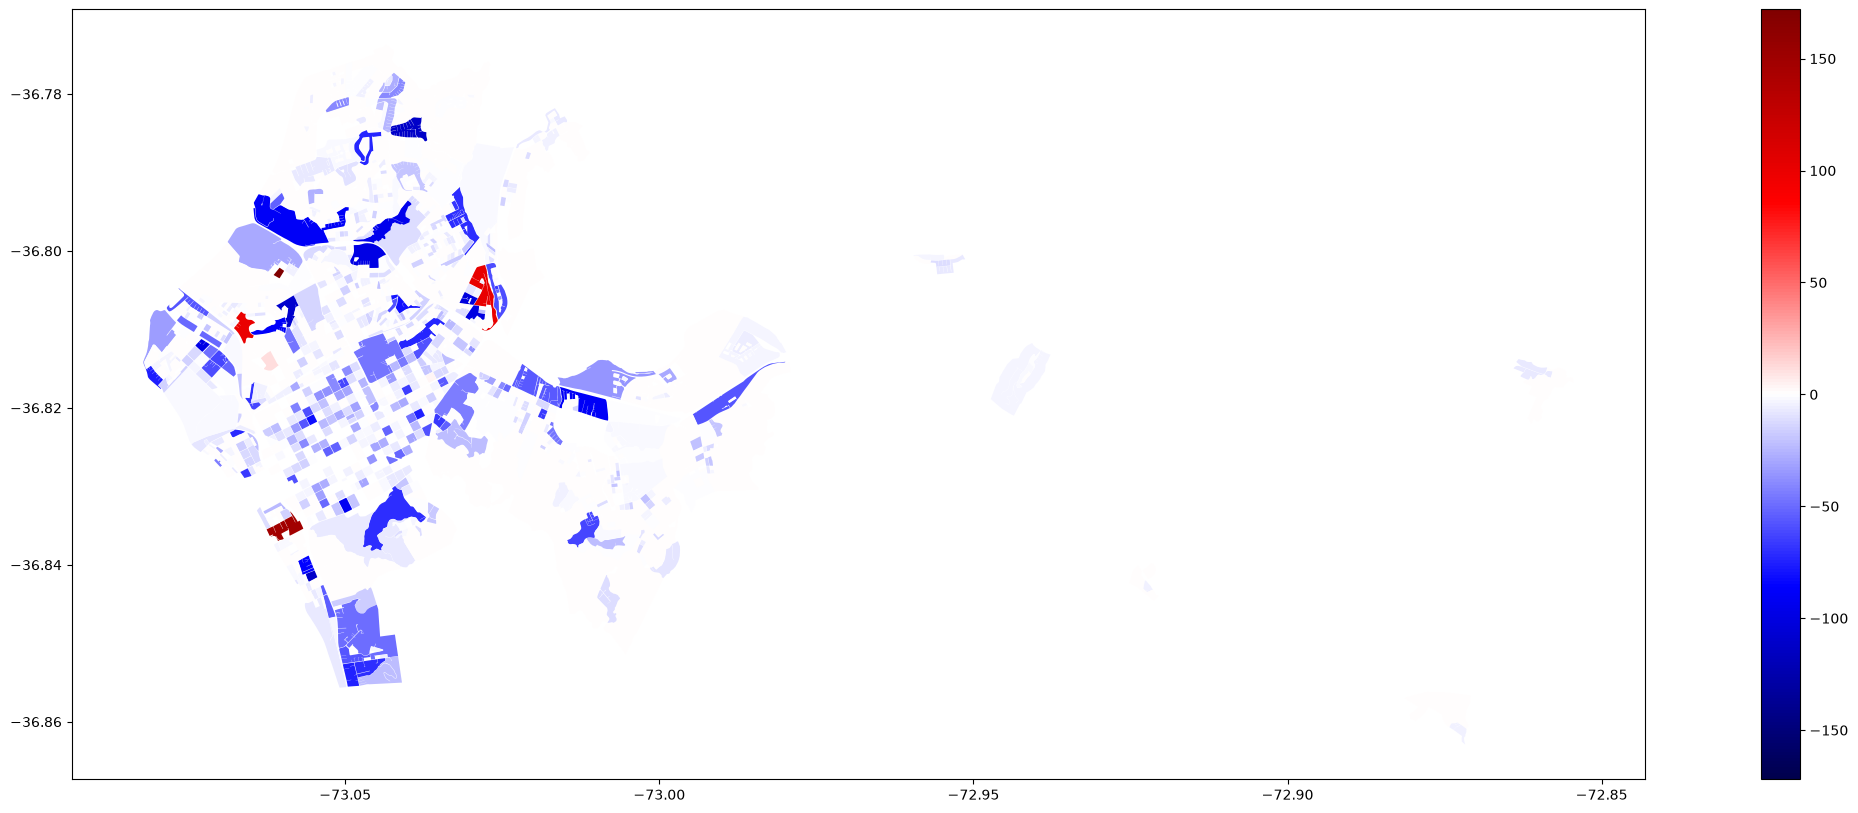

In [277]:
axis_size = np.max([np.abs(infered_blocks_gdf["diff"].max()), np.abs(infered_blocks_gdf["diff"].min())])
infered_blocks_gdf.plot(figsize=(30,10), column="diff", cmap="seismic", legend=True, vmin=-axis_size, vmax=axis_size)

In [294]:
infered_blocks_gdf

,MANZENT,SHAPE,count,n_vp,diff
0,8.101011e+12,"MULTIPOLYGON (((-73.048 -36.82416, -73.04797 -...",5,7.0,-2.0
1,8.101011e+12,"MULTIPOLYGON (((-73.0493 -36.82464, -73.04927 ...",43,57.0,-14.0
2,8.101011e+12,"MULTIPOLYGON (((-73.04621 -36.82468, -73.0467 ...",125,129.0,-4.0
3,8.101011e+12,"MULTIPOLYGON (((-73.05043 -36.82521, -73.04938...",23,25.0,-2.0
4,8.101011e+12,"MULTIPOLYGON (((-73.04795 -36.82438, -73.04797...",100,100.0,0.0
...,...,...,...,...,...
1535,8.101321e+12,"MULTIPOLYGON (((-73.0104 -36.82983, -73.00984 ...",23,23.0,0.0
1536,8.101322e+12,None,0,NaN,NaN
1537,8.101322e+12,None,0,NaN,NaN
1538,8.101322e+12,None,0,NaN,NaN


<Axes: >

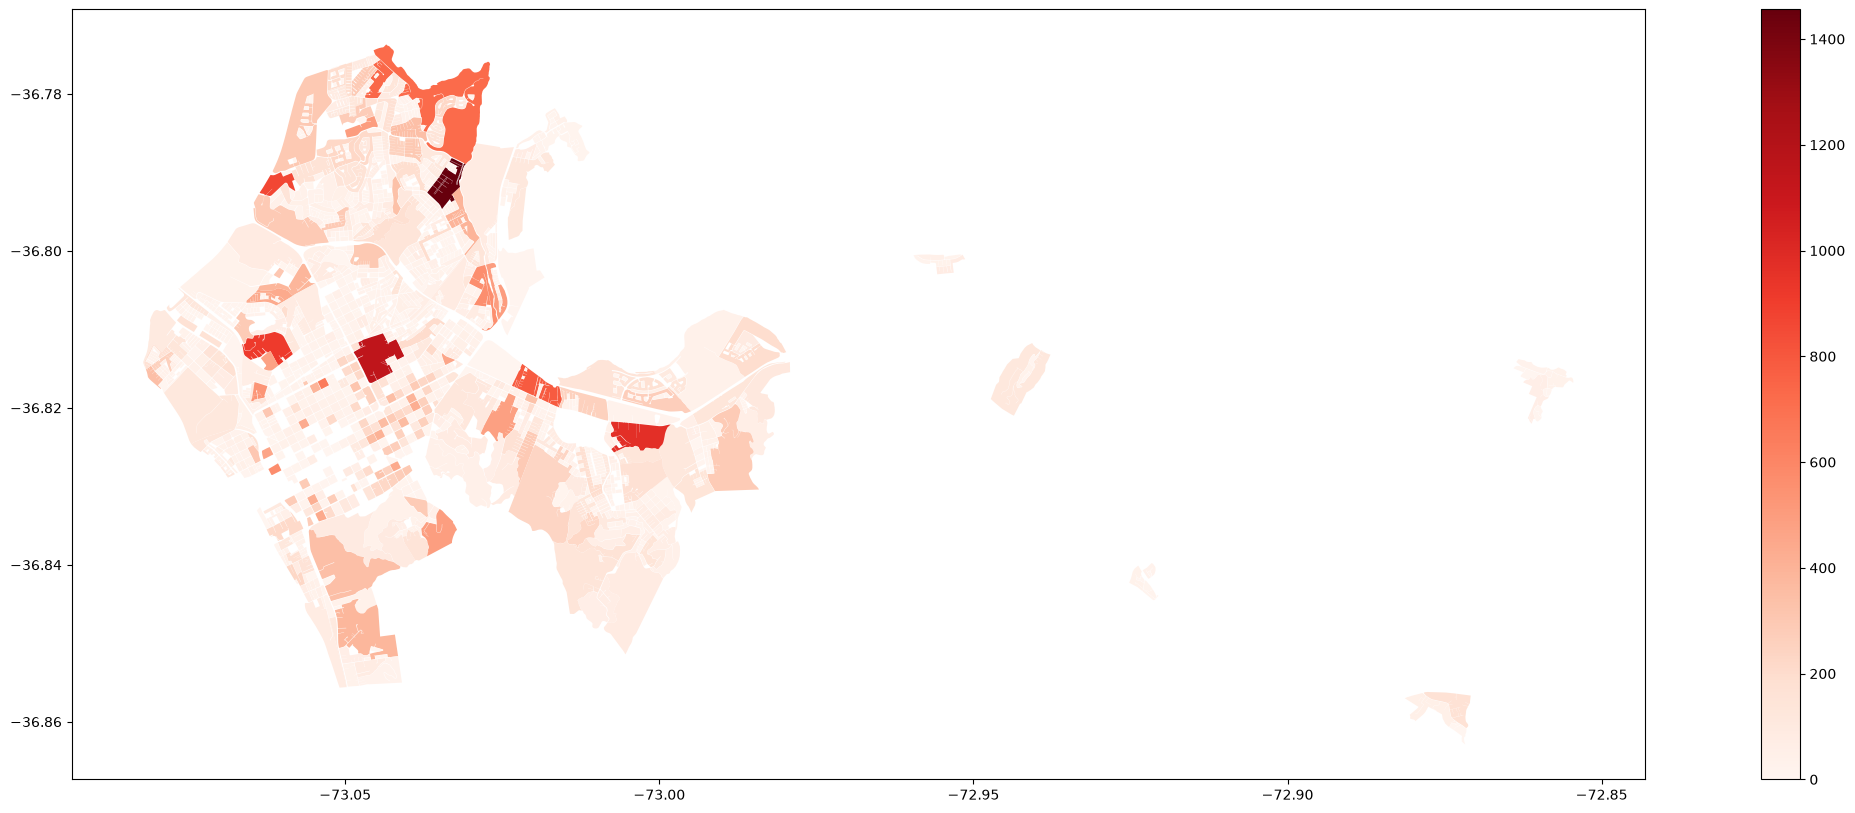

In [278]:
infered_blocks_gdf.plot(figsize=(30,10), column="count", cmap="Reds", legend=True)

<Axes: >

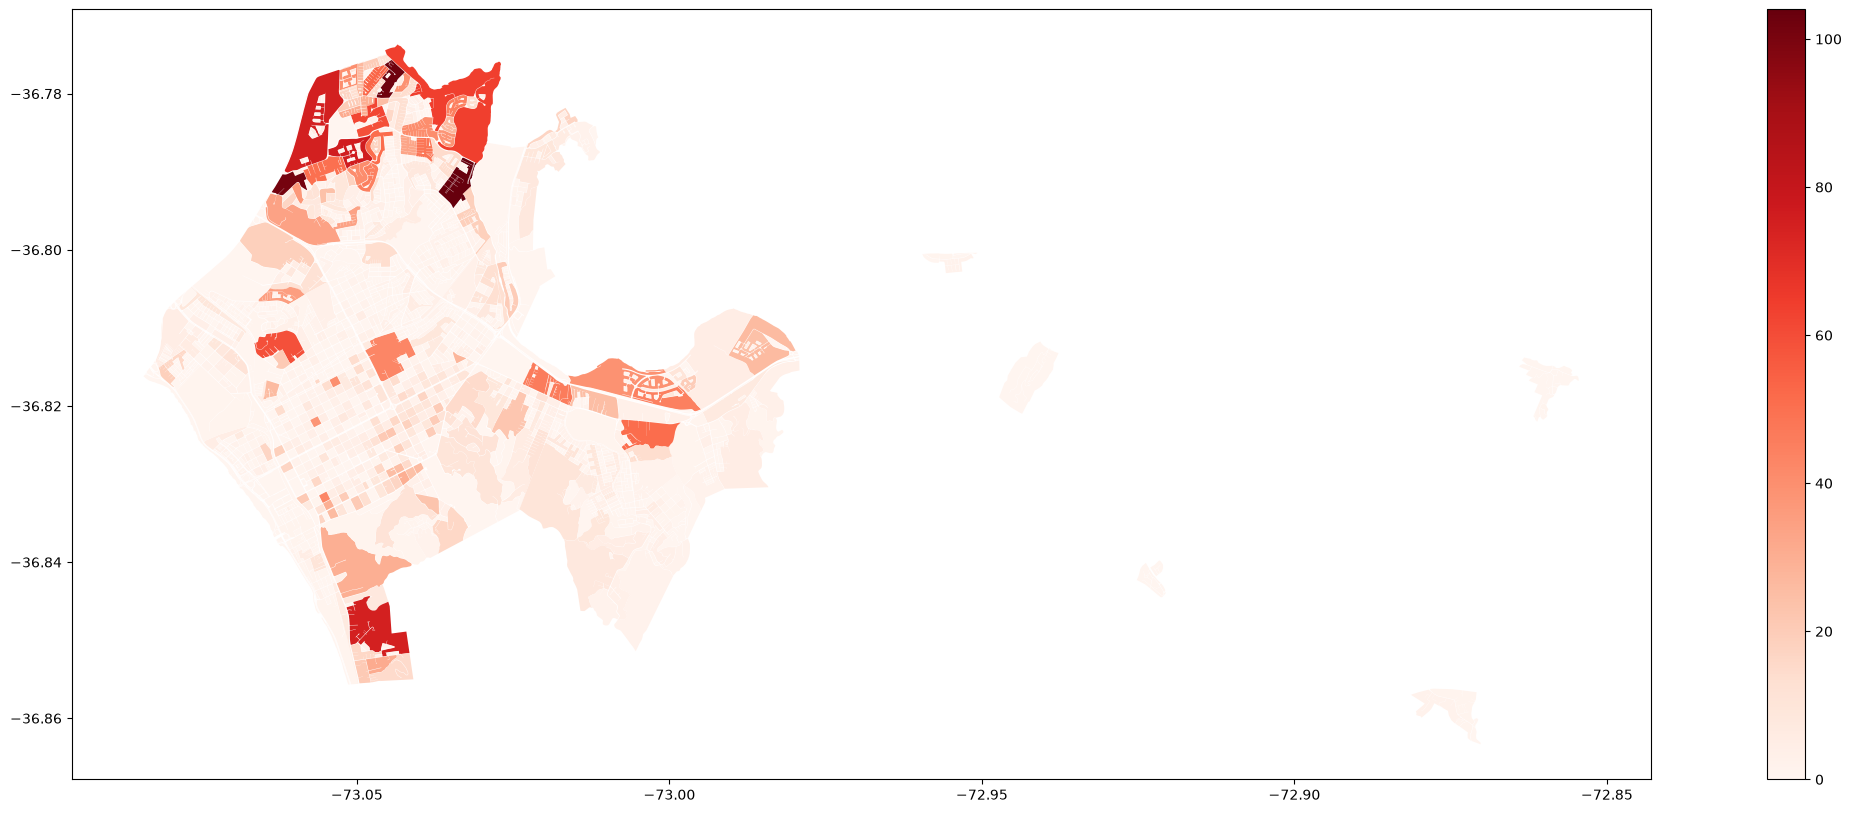

In [325]:
blocks_gdf.plot(figsize=(30,10), column="n_ciuo_1", cmap="Reds", legend=True)

In [323]:
tmp = per_df.merge(houses_df[["id_vivienda", "MANZENT"]], "left", "id_vivienda")
tmp = tmp[["cod_ciuo", "MANZENT"]]
tmp = tmp[tmp.cod_ciuo == 1]
tmp = tmp.groupby("MANZENT").sum().reset_index()
tmp

,MANZENT,cod_ciuo
0,8.101011e+12,1.0
1,8.101011e+12,11.0
2,8.101011e+12,3.0
3,8.101011e+12,4.0
4,8.101011e+12,1.0
...,...,...
1035,8.101321e+12,3.0
1036,8.101321e+12,5.0
1037,8.101321e+12,2.0
1038,8.101321e+12,2.0


<Axes: >

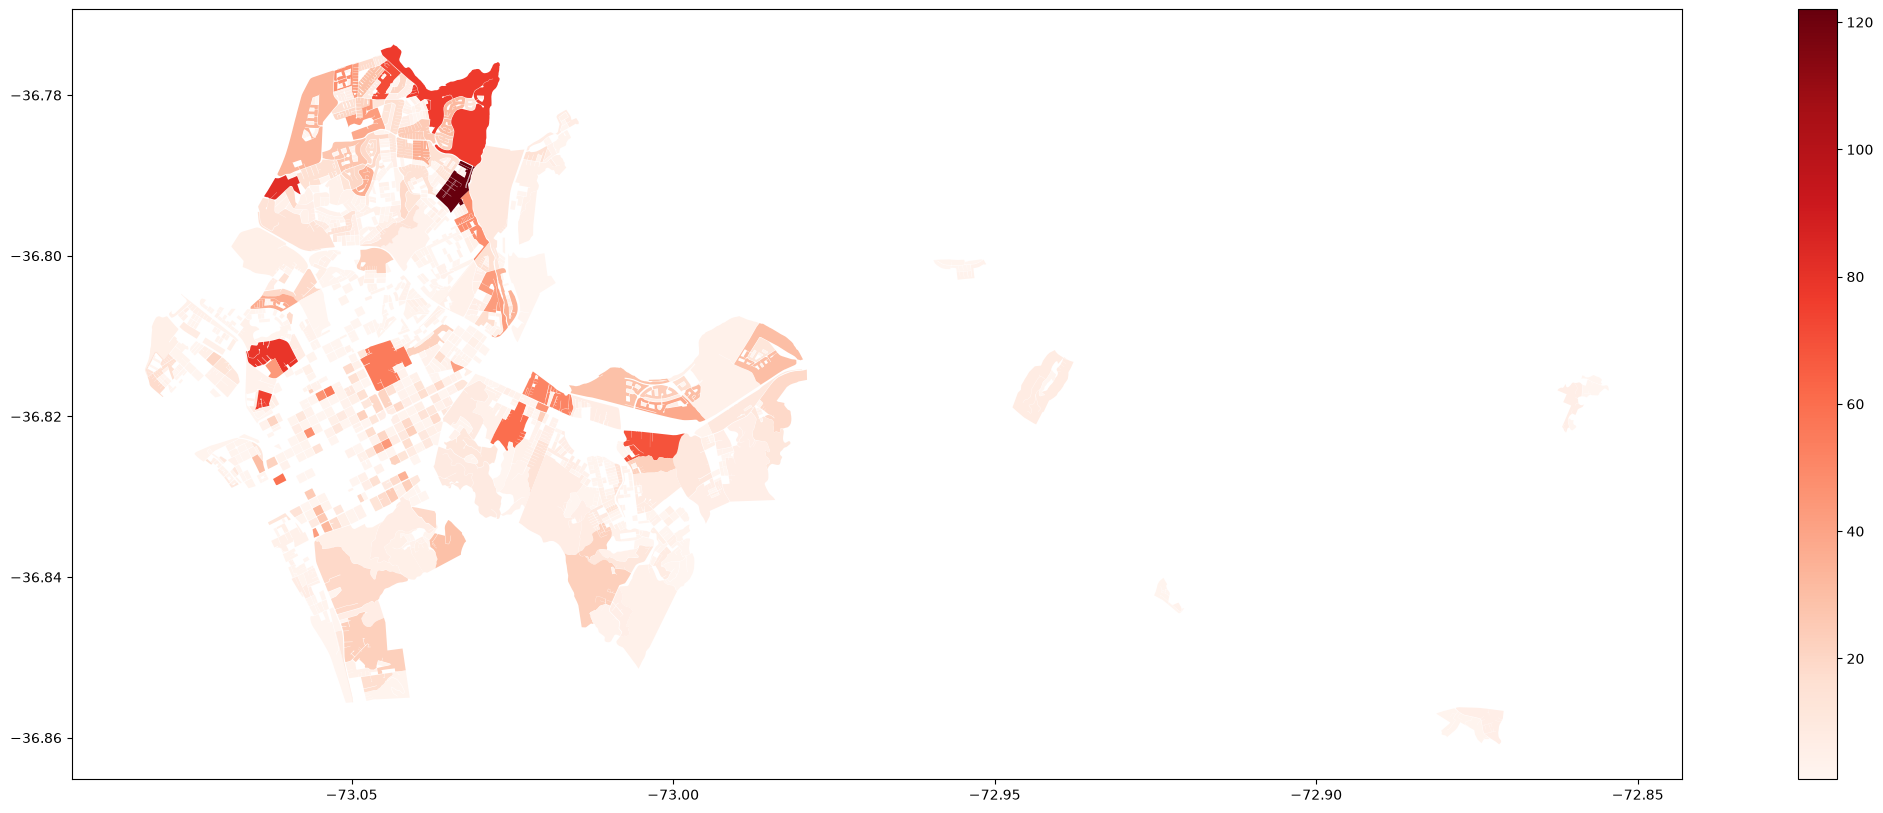

In [324]:
infered_blocks_gdf.merge(tmp[["cod_ciuo", "MANZENT"]], "left", on="MANZENT").plot(figsize=(30,10), column="cod_ciuo", cmap="Reds", legend=True)

the result shows a nice localization considering the adding of variables like the material of walls in houses\
however, this this result need to consider, besides of capacities and numbers of people and dorms in each house,\
other variables like education level and occupation to obtain a better result.